In [1]:
import xarray as xr
from climate_scenarios_2050.config import proj_base
from climate_scenarios_2050.utils import make_season_group
import proplot as pplt
import cartopy.crs as ccrs
import numpy as np
from pathlib import Path

In [2]:
fpath = Path('/projects/NS9873K/www/scenarios_2050/figures/wind_power')
fpath.mkdir(exist_ok=True,parents=True)

In [7]:
# wp_monthly = xr.open_dataset("/projects/NS9873K/owul/data/wind_power_production/monthly_agg/N175-120m_dry-dens_1940-2024.nc")
wp_monthly = xr.open_dataset("/projects/NS9873K/www/scenarios_2050/wind_power_production_dataset/monthly_aggregation/wsp100_GWAscaled_1940-2024.nc")

In [8]:
# load DJFM average NAO index
# year is the December year???
nao = xr.open_dataset(proj_base/'data/HadSLP/HadSLP_psl_EOF_full_index_DJFM_1850-2019_1.5deg.nc')
nao = nao.sel(mode=1,year=slice(wp_monthly.time.dt.year.min(),wp_monthly.time.dt.year.max())).squeeze().scores
# nao = xr.open_dataset(proj_base/'data/HadSLP/internal-NAO-variability_f-None.nc')
# nao = nao.sel(year=slice(wp_monthly.time.dt.year.min(),wp_monthly.time.dt.year.max())).squeeze().scores

In [9]:
def detrend_dim(da, dim, deg=1):
    # detrend along a single dimension
    p = da.polyfit(dim=dim, deg=deg)
    fit = xr.polyval(da[dim], p.polyfit_coefficients)
    return da - fit

def detrend(da, dims, deg=1):
    # detrend along multiple dimensions
    # only valid for linear detrending (deg=1)
    da_detrended = da
    for dim in dims:
        da_detrended = detrend_dim(da_detrended, dim, deg=deg)
    return da_detrended

In [19]:
# average wind power over entire year
season = make_season_group(wp_monthly,months_in_season=[1,2,3,4,5,6,7,8,9,10,11,12])
wp_seasonal = wp_monthly.groupby(season).sum().sel(year=slice(nao.year.min(),nao.year.max()))
# detrend wind power production:
# wp_seasonal_dt = detrend(wp_seasonal.energy,dims=["year"])
wp_seasonal_dt = detrend(wp_seasonal.wsp100,dims=["year"])
nao_dt = detrend(nao,dims=["year"])
nao_wp_corr = xr.corr(wp_seasonal_dt,nao_dt,dim="year")
# nao_wp_corr = xr.corr(wp_seasonal.wsp100,nao,dim="year")

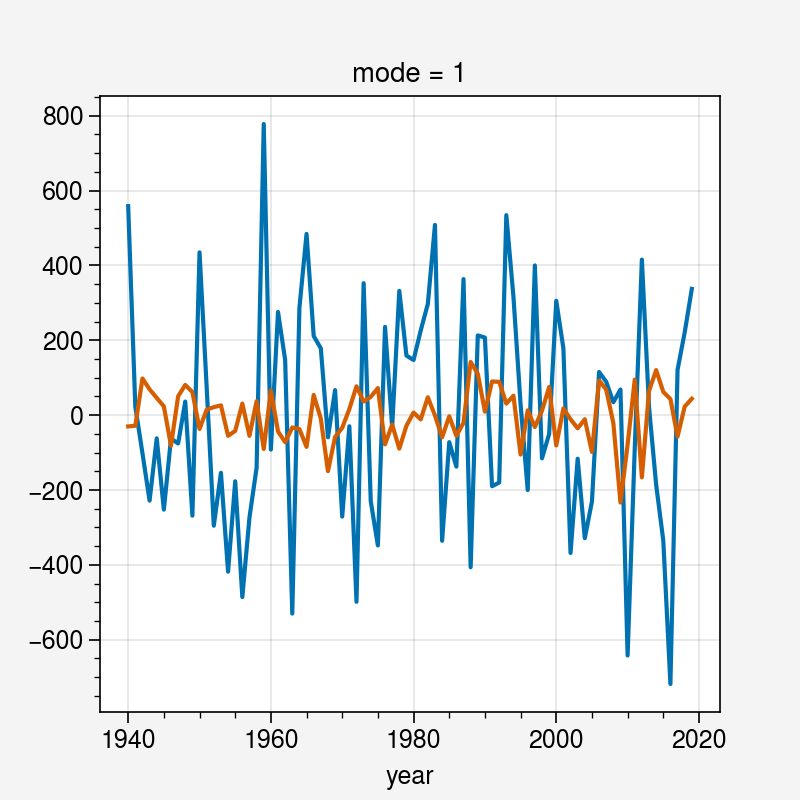

In [22]:
(wp_seasonal_dt.isel(longitude=100,latitude=100)*1e-1).plot()
nao_dt.plot()

In [35]:
nao_z = (nao_dt - nao_dt.mean())/nao_dt.std()
wp_z = (wp_seasonal_dt - wp_seasonal_dt.mean("year"))/wp_seasonal.std("year")

# filter:
nao_z = nao_z.rolling(year=8).mean()
wp_z = wp_z.rolling(year=8).mean()

<xarray.DataArray ()>
array(0.86847665)
Coordinates:
    mode       int64 1
    longitude  float32 14.5
    latitude   float32 66.75


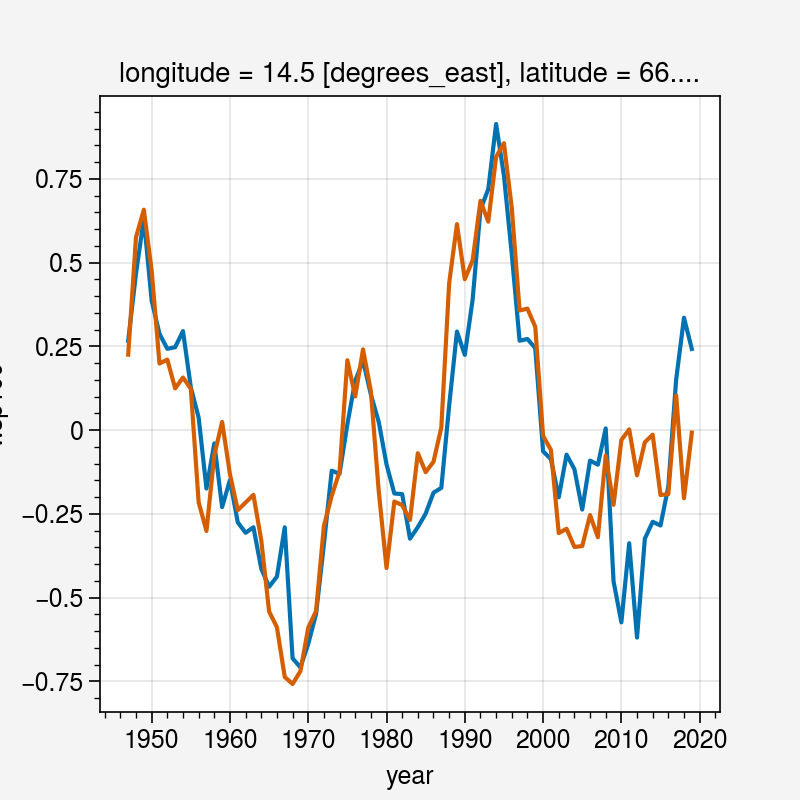

In [36]:
nao_z.plot()
wp_z.sel(latitude=66.75,longitude=14.5).wsp100.plot()
print(xr.corr(nao_z,wp_z.sel(latitude=66.75,longitude=14.5).wsp100))

<xarray.DataArray ()>
array(0.86847665)
Coordinates:
    mode       int64 1
    longitude  float32 14.5
    latitude   float32 66.75


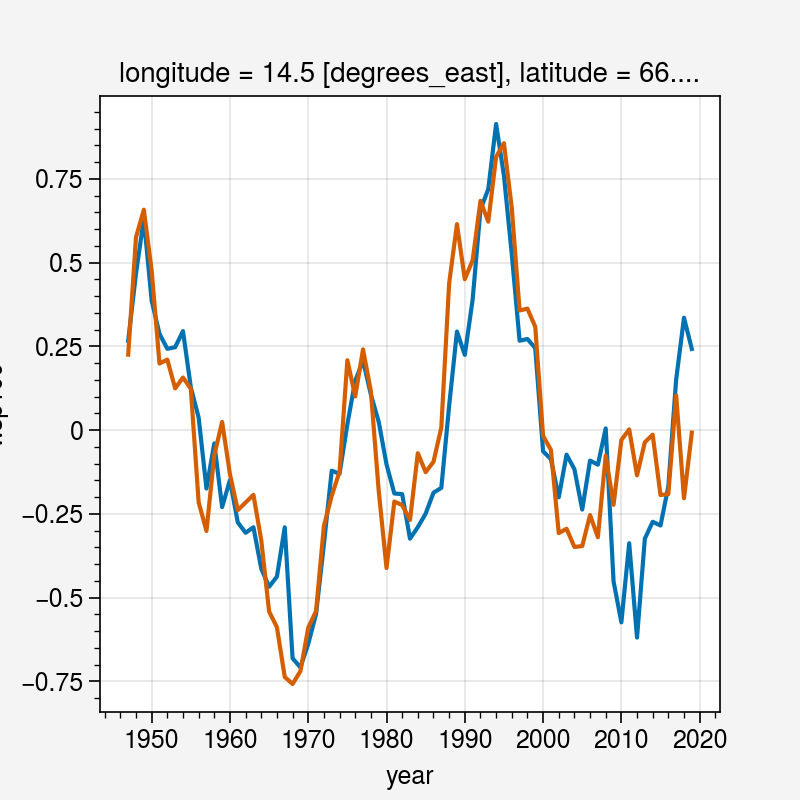

In [37]:
nao_z.plot()
# wp_z.sel(latitude=66.75,longitude=14.5).energy.plot()
wp_z.sel(latitude=66.75,longitude=14.5).wsp100.plot()
# print(xr.corr(nao_z,wp_z.sel(latitude=66.75,longitude=14.5).energy))
print(xr.corr(nao_z,wp_z.sel(latitude=66.75,longitude=14.5).wsp100))

In [38]:
nao_wp_corr.sel(latitude=66.75,longitude=14.5)

<xarray.DataArray ()>
array(0.59137877)
Coordinates:
    longitude  float32 14.5
    latitude   float32 66.75
    mode       int64 1

In [39]:
nao_wp_corr.sel(latitude=61.75,longitude=6.75)

<xarray.DataArray ()>
array(0.6945029)
Coordinates:
    longitude  float32 6.75
    latitude   float32 61.75
    mode       int64 1

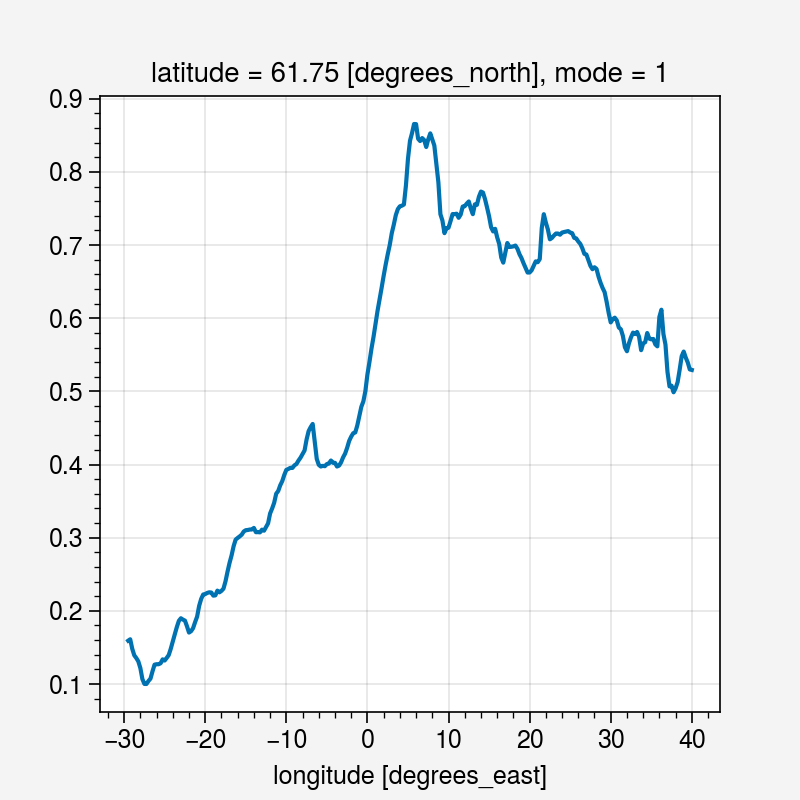

In [16]:
nao_wp_corr.sel(latitude=61.75).plot()

In [40]:
# correlation of running 8 year means:
nao_wp_corr_rm = xr.corr(wp_z.wsp100,nao_z,dim="year")


/projects/NS9873K/owul/conda/envs/climate_scenarios_2051/lib/python3.10/site-packages/cartopy/mpl/geoaxes.py:403: UserWarning: The `map_projection` keyword argument is deprecated, use `projection` to instantiate a GeoAxes instead.
  warnings.warn("The `map_projection` keyword argument is "


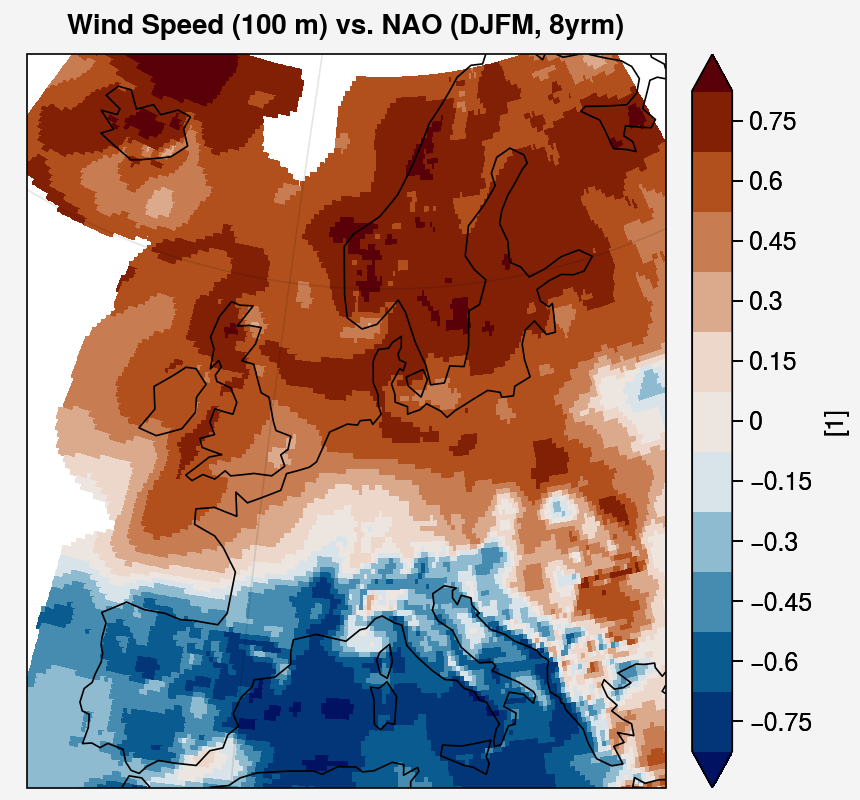

In [44]:
f,axs = pplt.subplots(figwidth=4.3,figheight=4,proj=ccrs.EuroPP(),suptitle="Wind Speed (100 m) vs. NAO (DJFM, 8yrm)")
pcm = axs.pcolormesh(
    nao_wp_corr_rm.longitude,nao_wp_corr_rm.latitude,nao_wp_corr_rm,
    values=np.arange(-.75,.751,.15),
    transform=ccrs.PlateCarree(),
    cmap_kw={'cut': -.1},
    cmap='vik',
    extend="both"
)
axs.format(
    coast=True,
)
# axs.plot(6.5,61.5§,transform=ccrs.PlateCarree(),marker='x',color='r')
axs.colorbar(pcm, loc='r', label="[1]")
# f.savefig(fpath/"corr_wpp-DJFM-nao-DJFM_8yrm.png",dpi=300,bbox_inches="tight")

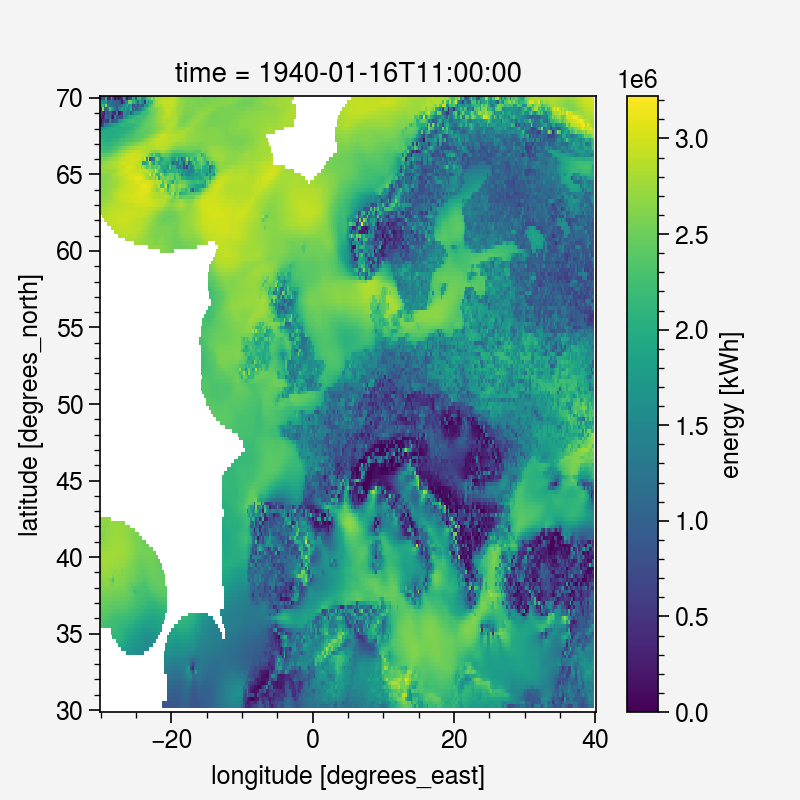

In [47]:
wp_monthly.energy.isel(time=0).plot()

In [22]:
dens = xr.open_mfdataset("/projects/NS9873K/owul/data/ERA5_density_processed/air_density_dry_at_120m_*.nc")

In [94]:
rho_d_prob = dens.rho_d.sel(lat=61.75,lon=5.25).load()

In [95]:
rho_d_unprob = dens.rho_d.sel(lat=61.5,lon=5.).load()

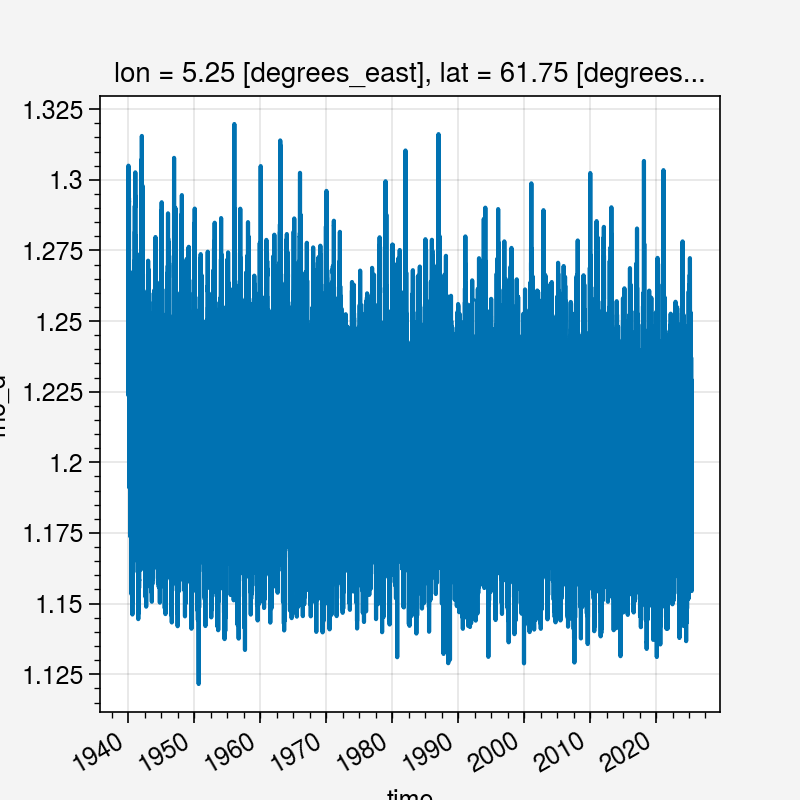

In [96]:
rho_d_prob.plot()

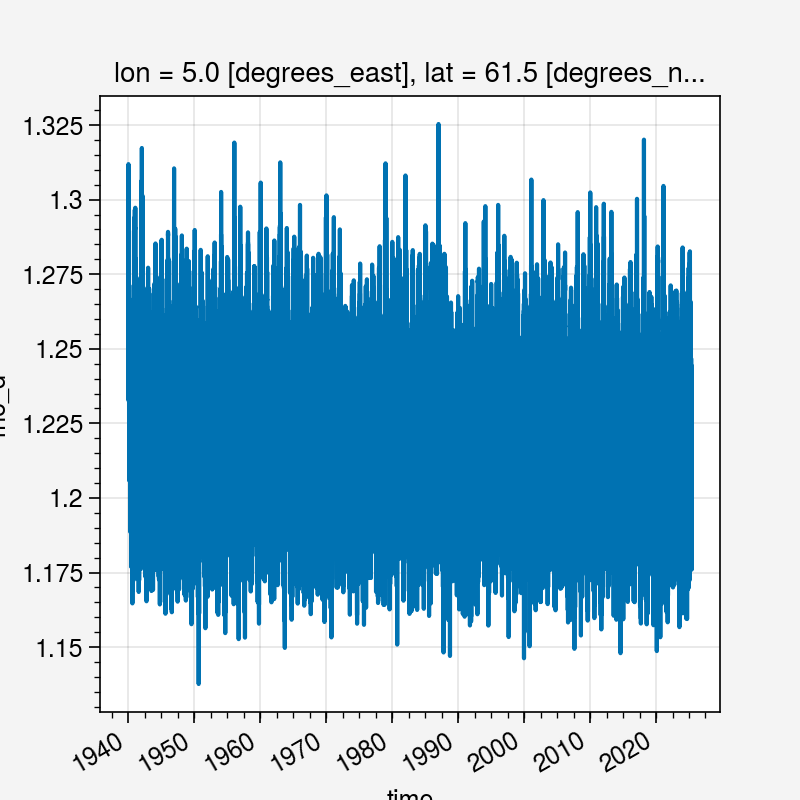

In [97]:

rho_d_unprob.plot()